<a href="https://colab.research.google.com/github/242031027-afk/Ai-search-algorithm-/blob/main/UCS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

UCS Path: ['A', 'B', 'E', 'F']


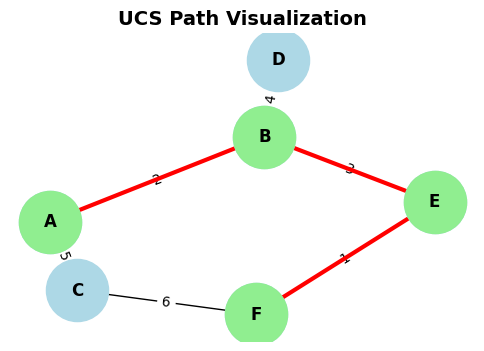

In [3]:
import networkx as nx
import matplotlib.pyplot as plt
import heapq

# Graph Definition
graph = {
    'A': {'B': 2, 'C': 5}, 'B': {'A': 2, 'D': 4, 'E': 3},
    'C': {'A': 5, 'F': 6}, 'D': {'B': 4},
    'E': {'B': 3, 'F': 1}, 'F': {'C': 6, 'E': 1}
}

def visualize_search(graph, path, title):
    G = nx.Graph()
    for node, edges in graph.items():
        for adj, weight in edges.items():
            G.add_edge(node, adj, weight=weight)
    pos = nx.spring_layout(G)
    plt.figure(figsize=(6, 4))
    plt.title(title, fontsize=14, fontweight='bold')
    nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=2000, font_weight='bold')
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, 'weight'))

    if path:
        path_edges = list(zip(path, path[1:]))
        nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color='red', width=3)
        nx.draw_networkx_nodes(G, pos, nodelist=path, node_color='lightgreen', node_size=2000)
    plt.show()

# UCS Algorithm
def ucs(graph, start, goal):
    queue = [(0, [start])]
    visited = set()
    while queue:
        cost, path = heapq.heappop(queue)
        node = path[-1]
        if node in visited: continue
        visited.add(node)
        if node == goal: return path
        for adjacent, weight in graph.get(node, {}).items():
            if adjacent not in visited:
                heapq.heappush(queue, (cost + weight, path + [adjacent]))
    return []

# Run & Visualize
path = ucs(graph, 'A', 'F')
print("UCS Path:", path)
visualize_search(graph, path, "UCS Path Visualization")
